<a href="https://colab.research.google.com/github/hyo-yeon-lee/MCNB-Probability-and-Statistics/blob/main/lecture03_chi2_exercises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Exercise 1: Permutation test

Here, I am providing code to run a permutation test on the fmri toy example we just covered. Please answer the following questions:

1. Point to the line where we compute the value of interest we compute for our observed sample.
2. Explain why ```combined_data = np.array(fmri_data_A + fmri_data_B)```, and how this related to the shuffling.
3. Point to the line where the shuffling happens. Is this "in place shuffling", or not? What does this mean?
4. Explain the lines ```perm_A = combined_data[:len(fmri_data_A)]``` and ```perm_B = combined_data[len(fmri_data_A):]```.
5. The ```p_value = ...``` line is very compressed code. See if you can understand it. Is this a 1-tailed or 2-tailed test?

Observed Difference: 8.60
P-value: 0.008
Time taken: 2.61649227142334 seconds


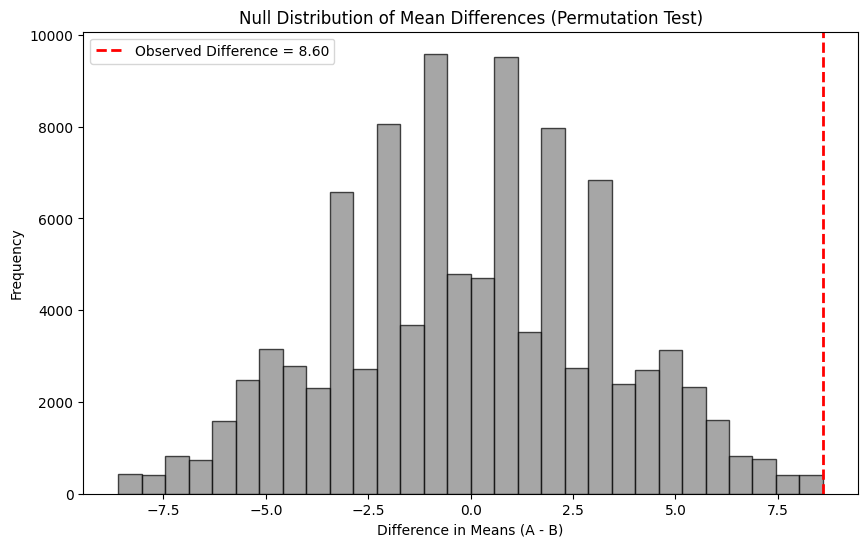

Reject the null hypothesis: Significant difference between groups.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Sample fMRI data
fmri_data_A = [103, 99, 98, 101, 99]
fmri_data_B = [90, 87, 96, 93, 91]

# Observed difference in means
observed_diff = np.mean(fmri_data_A) - np.mean(fmri_data_B)
print(f"Observed Difference: {observed_diff:.2f}")

# Combine data
combined_data = np.array(fmri_data_A + fmri_data_B) # adding lists makes a longer list with all elements. Then we turn the longer list into a np array.
n_permutations = 100000
perm_diffs = []

import time
start = time.time()
# Permutation test
for _ in range(n_permutations):
    np.random.shuffle(combined_data)
    perm_A = combined_data[:len(fmri_data_A)]
    perm_B = combined_data[len(fmri_data_A):]
    perm_diff = np.mean(perm_A) - np.mean(perm_B)
    perm_diffs.append(perm_diff)

# Convert permutation differences to a numpy array for easier plotting
perm_diffs = np.array(perm_diffs)

# Calculate p-value (two-tailed)
p_value = np.mean(np.abs(perm_diffs) >= np.abs(observed_diff))
print(f"P-value: {p_value:.3f}")

end = time.time()
print(f"Time taken: {end - start} seconds")

# Plot the null distribution of permuted differences
plt.figure(figsize=(10, 6))
plt.hist(perm_diffs, bins=30, color='grey', edgecolor='black', alpha=0.7)
plt.axvline(observed_diff, color='red', linestyle='dashed', linewidth=2, label=f'Observed Difference = {observed_diff:.2f}')
plt.xlabel("Difference in Means (A - B)")
plt.ylabel("Frequency")
plt.title("Null Distribution of Mean Differences (Permutation Test)")
plt.legend()
plt.show()

# Conclusion
alpha = 0.05
if p_value < alpha:
    print("Reject the null hypothesis: Significant difference between groups.")
else:
    print("Fail to reject the null hypothesis: No significant difference between groups.")


>Note: Typically, in day-to-day work, you will just use the [scipy.permutation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.permutation_test.html) function, which is very easy. Here is how to do it.

In [2]:
from scipy.stats import permutation_test

# Permutation test can be applied for any statistic
# Here, we are interested in the difference in means.
# We need to create a function that does that,
# and then we'll pass it to the permutation_test function
def mean_difference(x, y):
    return np.mean(x) - np.mean(y)

start = time.time()
# Perform the permutation test
result = permutation_test((fmri_data_A, fmri_data_B),
                          statistic=mean_difference,
                          alternative="two-sided",
                          n_resamples=100000,
                          random_state=0)
end = time.time()
print(f"Time taken: {end - start} seconds")
# Output the test statistic and p-value
print(f"Permutation test statistic: {result.statistic}")
print(f"P-value: {result.pvalue}")

Time taken: 0.01198720932006836 seconds
Permutation test statistic: 8.599999999999994
P-value: 0.007936507936507936


#Exercise 2: Chi-squared

In this exercise, we will use Chi2 to test is a die is fair.

We will do so in two ways:

1. We will do what you will do 99.99% of the time in practice: use a pre-programmed function to do the test.

2. In order to get a better understanding of what is going on, we will then also explicitly compute the chi2 statistic and compare it to the chi2 distribution with the appropriate degrees of freedom.

Import stuff

In [3]:
import numpy as np
from scipy.stats import chisquare
import matplotlib.pyplot as plt
from scipy.stats import chi2, chisquare

Write down the observed dice rolls we got. You can play around with the values if you want.

In [4]:
observed_rolls = [1, 3, 4, 4, 5, 5, 6, 6, 6, 6]

###Part I: using chi2 from scipy.stats.

We will use the [chisquare](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chisquare.html) function from ```scipy.stats```.

First, we need to create a list called ```observed_frequencies``` which contains the observed frequencies for the chi2 test, i.e., the number of times we got each value from 1-6. For this:
- use a for loop to go over each value from 1-6.
- use the [count](https://www.w3schools.com/python/ref_list_count.asp) method (see link for documentation) to count how many time each value occurs in observed rolls.

In [8]:
# Count the observed frequency of each die face (1 to 6)
observed_frequencies = np.zeros(6)
# Replace this line with your code:
for i in range(6):
  observed_frequencies[i] = observed_rolls.count(i+1)

print(observed_frequencies)

[1. 0. 1. 2. 2. 4.]


Now, look at the online [documentation for the chisquare](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chisquare.html) function from ```scipy.stats```, and run the test. Report if we should conclude whether the die is fair or not.

In [9]:
# use chisquare from scipy.stats to run the test

# Replace this line with your code:
chisquare(observed_frequencies, axis = 0)

Power_divergenceResult(statistic=np.float64(5.599999999999999), pvalue=np.float64(0.3471050682817159))

###Part II: computing the chi2 value explicitly.

Now, let's repeat the sam etest, but we'll do a bit more of it by hand to get a feeling for how the chisquared statistic is computed.

First, let's create the same list called ```observed_frequencies``` as earlier *(note: you can copy-paste from earlier -- this is not striclty needed, as we already computed it above, but I'm including it for completeness)*.

In [10]:
# Count the observed frequency of each die face (1 to 6)
observed_frequencies = np.zeros(6)
# Replace this line with your code:
for i in range(6):
  observed_frequencies[i] = observed_rolls.count(i+1)

print(observed_frequencies)

[1. 0. 1. 2. 2. 4.]


Second, let's create a list called ```expected_frequencies``` to contain the expected frequencies for the chi2 test, i.e., the number of times we'd expect to get each value form 1-6 if the die was fair.

I am giving you the code for this, you don't need to do anything.

In [11]:
# We expect each face to occur equally, so for 10 rolls, each face should occur 10 / 6 times on average.
n_rolls = len(observed_rolls)
n_sides = 6
expected_frequency = n_rolls / n_sides  # Expected frequency for each die face
expected_frequencies = np.array([expected_frequency] * n_sides)
print("Expected frequencies for each face:", expected_frequencies)

Expected frequencies for each face: [1.66666667 1.66666667 1.66666667 1.66666667 1.66666667 1.66666667]


Now, let's compute the chi2 statistic. Fill in the blanks here.

(note: index 0 in our lists declared above contains the value for a dice value of 1 because python uses 0-indexing).

>**Note:** This is the main part of this exercise that I want you to really understand.

In [13]:
# Explicitly compute Chi2
chi2_statistic = 0
for i in range(6):
    this_observed_frequency = observed_frequencies[i]
    this_expected_frequency = expected_frequencies[i]
    print(f"Observed: {this_observed_frequency}, Expected: {this_expected_frequency}")
    chi2_statistic += np.square(this_observed_frequency - this_expected_frequency) / this_expected_frequency
print(f"Chi-square statistic: {chi2_statistic}")

Observed: 1.0, Expected: 1.6666666666666667
Observed: 0.0, Expected: 1.6666666666666667
Observed: 1.0, Expected: 1.6666666666666667
Observed: 2.0, Expected: 1.6666666666666667
Observed: 2.0, Expected: 1.6666666666666667
Observed: 4.0, Expected: 1.6666666666666667
Chi-square statistic: 5.599999999999999


Next, we plot the null distribution PDF (probability distribution function), along with a vertical line at the location of our sample's chi2, which we just computed above.

To get the PDF, we use the [chi2](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2.html) object from ```scipy.stats``` (which we imported at the top of. the script).

I am giving you the code for this. Understanding how to retrieve the PDF is not part of the required knowledge for this course. Of course, feel free to look at the documentation at home if you are interested (but please, not during the class as we don' have time).

>**Note:** As you can see in the first line, we are using the chi2 distribution for 5 degrees of freedom, because the dice have 6 possible values and for chi2, df = n_groups-1.

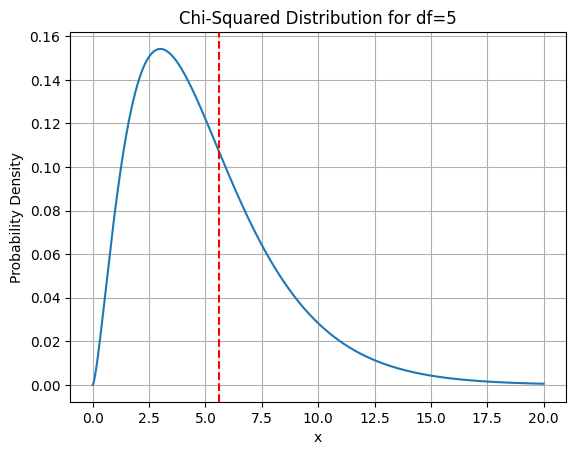

In [14]:
pdf = chi2.pdf(np.linspace(0, 20, 1000), df=5) # this returns the chi2 pdf

plt.figure()
plt.plot(np.linspace(0, 20, 1000), pdf)
plt.axvline(x=chi2_statistic, color='r', linestyle='--') # adds the vertical line
plt.title('Chi-Squared Distribution for df=5')
plt.xlabel('x')
plt.ylabel('Probability Density')
plt.grid(True)
plt.show()

Now, we get the p-value. This means: we get the area under the curve to the right of the chi2 value we observed.

This can be done using the cumulative distribution function (CDF), which we also get form scipy.stats' [chi2](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2.html) object.

This part of the code is not required knowledge for you. Again, feel free to look at the documentation at home if you are interested (but please, not during the class as we don' have time).

I am giving you the code for this.

In [15]:
# Get p-value
p_value = 1 - chi2.cdf(chi2_statistic, df=5)
print(f"P-value: {p_value}")

P-value: 0.34710506828171583


Finally, please complete the following if statement so that we reject the null in the right cases.

In [17]:
# Conclusion based on the p-value
alpha = 0.05  # Significance level
if p_value > alpha:
    print("Reject the null hypothesis: The die is not fair.")
else:
    print("Fail to reject the null hypothesis: The die is fair.")

Reject the null hypothesis: The die is not fair.
